# Data import
What datasets are you using, later explain the variables a little bit more


In [8]:
import pandas as pd
import os
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder


In [9]:
print("Current Working Directory:", os.getcwd())


# Load the datasets
mat_data = pd.read_csv('../../student/student-mat.csv', sep=';')
por_data = pd.read_csv('../../student/student-por.csv', sep=';')

# View the first few rows
print(mat_data.head())
print(por_data.head())

Current Working Directory: c:\Users\ivoga\Documents\Git local repositories\projekt-R\testiranje\klasifikacijski_modeli\individual
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5     

In [10]:
print(mat_data.describe())
print(por_data.describe())

              age        Medu        Fedu  traveltime   studytime    failures  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean    16.696203    2.749367    2.521519    1.448101    2.035443    0.334177   
std      1.276043    1.094735    1.088201    0.697505    0.839240    0.743651   
min     15.000000    0.000000    0.000000    1.000000    1.000000    0.000000   
25%     16.000000    2.000000    2.000000    1.000000    1.000000    0.000000   
50%     17.000000    3.000000    2.000000    1.000000    2.000000    0.000000   
75%     18.000000    4.000000    3.000000    2.000000    2.000000    0.000000   
max     22.000000    4.000000    4.000000    4.000000    4.000000    3.000000   

           famrel    freetime       goout        Dalc        Walc      health  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean     3.944304    3.235443    3.108861    1.481013    2.291139    3.554430   
std      0.896659    0.9988

# Encoding the data
binary features are encoded using label encoding (0 and 1), 
while for categorical features one-hot encoding is used.
As for the numerical features, they are normilized using min-max scaling.

In [11]:
# encoding the binary features
binary_features = ['school', 'sex', 'address', 'famsize', 'Pstatus', 
                   'schoolsup', 'famsup', 'paid', 'activities', 
                   'nursery', 'higher', 'internet', 'romantic']

label_encoder = LabelEncoder()
for feature in binary_features:
    mat_data[feature] = label_encoder.fit_transform(mat_data[feature])
    por_data[feature] = label_encoder.fit_transform(por_data[feature])


# one-hot encoding the categorical features
categorical_features = ['Mjob', 'Fjob', 'reason', 'guardian']

mat_data = pd.get_dummies(mat_data, columns=categorical_features, drop_first=True)
por_data = pd.get_dummies(por_data, columns=categorical_features, drop_first=True)

# normalizing numeric features using min-max scaling
numeric_features = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 
                    'failures', 'famrel', 'freetime', 'goout', 'Dalc', 
                    'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

scaler = MinMaxScaler()
mat_data[numeric_features] = scaler.fit_transform(mat_data[numeric_features])
por_data[numeric_features] = scaler.fit_transform(por_data[numeric_features])



# Binary Classification for Math data
Predict whether G3 is above or below a threshold (e.g., 0.5)


In [12]:
# Create a binary target variable
mat_data['G3_binary'] = (mat_data['G3'] > 0.5).astype(int)

# Define features and target
X_binary_mat = mat_data.drop(columns=['G3', 'G3_binary'])
y_binary_mat = mat_data['G3_binary']

In [13]:
# Split the data
X_train_binary_mat, X_test_binary_mat, y_train_binary_mat, y_test_binary_mat = train_test_split(
    X_binary_mat, y_binary_mat, test_size=0.2, random_state=42
)


In [14]:
# Train Support Vector Machine Classifier
svm_binary_mat = SVC(kernel='linear', random_state=42)
svm_binary_mat.fit(X_train_binary_mat, y_train_binary_mat)

SVC(kernel='linear', random_state=42)

Binary Classification Results for mat_data:
Accuracy: 0.9620253164556962
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.95      0.96        38
           1       0.95      0.98      0.96        41

    accuracy                           0.96        79
   macro avg       0.96      0.96      0.96        79
weighted avg       0.96      0.96      0.96        79

Confusion Matrix:
[[36  2]
 [ 1 40]]


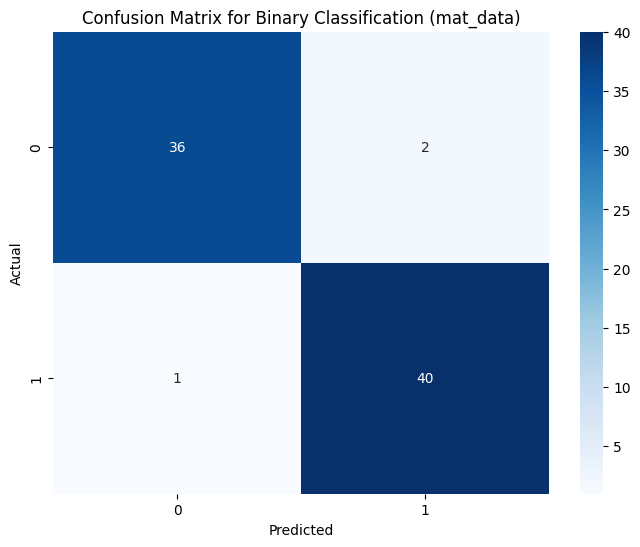

In [ ]:
# Predict and evaluate
y_pred_binary_mat = svm_binary_mat.predict(X_test_binary_mat)
print("Binary Classification Results for math data:")
print(f"Accuracy: {accuracy_score(y_test_binary_mat, y_pred_binary_mat)}")
print("Classification Report:")
print(classification_report(y_test_binary_mat, y_pred_binary_mat))
print("Confusion Matrix:")
print(confusion_matrix(y_test_binary_mat, y_pred_binary_mat))

# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_binary_mat, y_pred_binary_mat), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Binary Classification (Math data)")
plt.show()

# 5-Level Classification
Categorize G3 into 5 performance levels

In [16]:
# Create 5 levels for the target variable (G3)
mat_data['G3_5_levels'] = pd.cut(
    mat_data['G3'],
    bins=5,
    labels=[0, 1, 2, 3, 4],
    include_lowest=True
)

In [17]:
# Define features and target
X_5_levels_mat = mat_data.drop(columns=['G3', 'G3_binary', 'G3_5_levels'])
y_5_levels_mat = mat_data['G3_5_levels']

In [18]:
# Split the data
X_train_5_mat, X_test_5_mat, y_train_5_mat, y_test_5_mat = train_test_split(
    X_5_levels_mat, y_5_levels_mat, test_size=0.2, random_state=42
)

In [19]:
# Train Support Vector Machine Classifier
svm_5_levels_mat = SVC(kernel='linear', decision_function_shape='ovr', random_state=42)
svm_5_levels_mat.fit(X_train_5_mat, y_train_5_mat)

SVC(kernel='linear', random_state=42)

5-Level Classification Results for mat_data:
Accuracy: 0.6329113924050633
Classification Report:
              precision    recall  f1-score   support

           0       0.14      0.20      0.17         5
           1       0.70      0.41      0.52        17
           2       0.60      0.81      0.69        26
           3       0.82      0.72      0.77        25
           4       0.60      0.50      0.55         6

    accuracy                           0.63        79
   macro avg       0.57      0.53      0.54        79
weighted avg       0.66      0.63      0.63        79

Confusion Matrix:
[[ 1  1  3  0  0]
 [ 4  7  6  0  0]
 [ 2  2 21  1  0]
 [ 0  0  5 18  2]
 [ 0  0  0  3  3]]


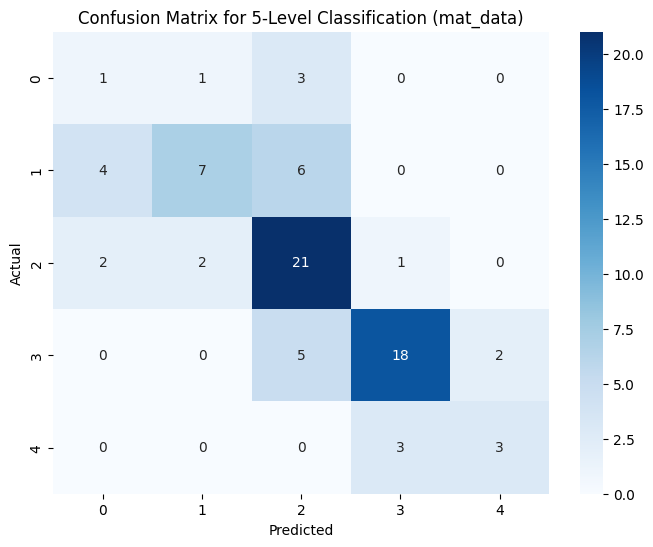

In [20]:
# Predict and evaluate
y_pred_5_mat = svm_5_levels_mat.predict(X_test_5_mat)
print("5-Level Classification Results for mat_data:")
print(f"Accuracy: {accuracy_score(y_test_5_mat, y_pred_5_mat)}")
print("Classification Report:")
print(classification_report(y_test_5_mat, y_pred_5_mat))
print("Confusion Matrix:")
print(confusion_matrix(y_test_5_mat, y_pred_5_mat))

# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_5_mat, y_pred_5_mat), annot=True, fmt="d", cmap="Blues", 
            xticklabels=[0, 1, 2, 3, 4], yticklabels=[0, 1, 2, 3, 4])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for 5-Level Classification (mat_data)")
plt.show()


# Binary Classification for Portuguese data
Predict whether G3 is above or below a threshold (e.g., 0.5)

In [21]:
# Create a binary target variable
por_data['G3_binary'] = (por_data['G3'] > 0.5).astype(int)

# Define features and target
X_binary_por = por_data.drop(columns=['G3', 'G3_binary'])
y_binary_por = por_data['G3_binary']

In [22]:
# Split the data
X_train_binary_por, X_test_binary_por, y_train_binary_por, y_test_binary_por = train_test_split(
    X_binary_por, y_binary_por, test_size=0.2, random_state=42
)

In [23]:
# Train Support Vector Machine Classifier
svm_binary_por = SVC(kernel='linear', random_state=42)
svm_binary_por.fit(X_train_binary_por, y_train_binary_por)

SVC(kernel='linear', random_state=42)

Binary Classification Results for por_data:
Accuracy: 0.9076923076923077
Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.60      0.60        15
           1       0.95      0.95      0.95       115

    accuracy                           0.91       130
   macro avg       0.77      0.77      0.77       130
weighted avg       0.91      0.91      0.91       130

Confusion Matrix:
[[  9   6]
 [  6 109]]


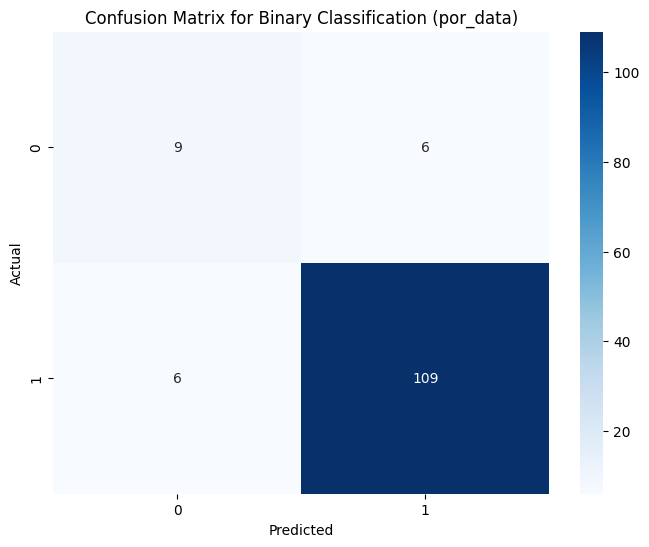

In [24]:
# Predict and evaluate
y_pred_binary_por = svm_binary_por.predict(X_test_binary_por)
print("Binary Classification Results for por_data:")
print(f"Accuracy: {accuracy_score(y_test_binary_por, y_pred_binary_por)}")
print("Classification Report:")
print(classification_report(y_test_binary_por, y_pred_binary_por))
print("Confusion Matrix:")
print(confusion_matrix(y_test_binary_por, y_pred_binary_por))

# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_binary_por, y_pred_binary_por), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Binary Classification (por_data)")
plt.show()

# 5-Level Classification for Portuguese data
Categorize G3 into 5 performance levels


In [25]:
# Create 5 levels for the target variable (G3)
por_data['G3_5_levels'] = pd.cut(
    por_data['G3'],
    bins=5,
    labels=[0, 1, 2, 3, 4],
    include_lowest=True
)

In [26]:
# Define features and target
X_5_levels_por = por_data.drop(columns=['G3', 'G3_binary', 'G3_5_levels'])
y_5_levels_por = por_data['G3_5_levels']

In [27]:
# Split the data
X_train_5_por, X_test_5_por, y_train_5_por, y_test_5_por = train_test_split(
    X_5_levels_por, y_5_levels_por, test_size=0.2, random_state=42
)

In [28]:
# Train Support Vector Machine Classifier
svm_5_levels_por = SVC(kernel='linear', decision_function_shape='ovr', random_state=42)
svm_5_levels_por.fit(X_train_5_por, y_train_5_por)

SVC(kernel='linear', random_state=42)

5-Level Classification Results for por_data:
Accuracy: 0.7461538461538462
Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.50      0.50         2
           1       0.00      0.00      0.00         1
           2       0.85      0.74      0.79        54
           3       0.66      0.86      0.75        51
           4       0.86      0.55      0.67        22

    accuracy                           0.75       130
   macro avg       0.57      0.53      0.54       130
weighted avg       0.76      0.75      0.74       130

Confusion Matrix:
[[ 1  0  1  0  0]
 [ 0  0  1  0  0]
 [ 1  0 40 13  0]
 [ 0  0  5 44  2]
 [ 0  0  0 10 12]]


c:\Users\ivoga\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\ivoga\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\ivoga\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

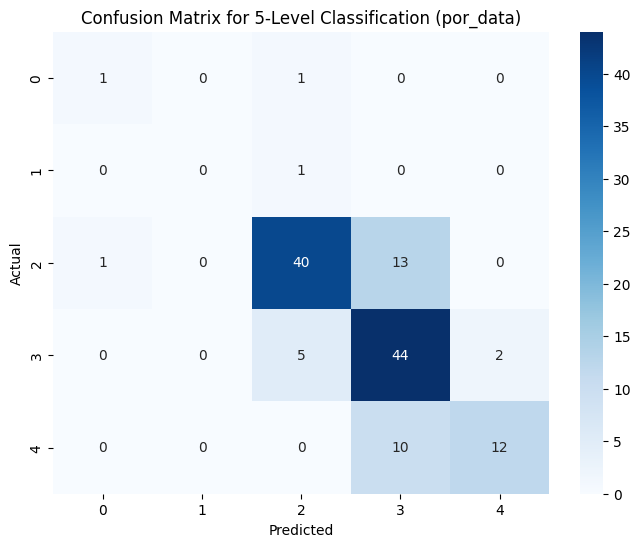

In [29]:
# Predict and evaluate
y_pred_5_por = svm_5_levels_por.predict(X_test_5_por)
print("5-Level Classification Results for por_data:")
print(f"Accuracy: {accuracy_score(y_test_5_por, y_pred_5_por)}")
print("Classification Report:")
print(classification_report(y_test_5_por, y_pred_5_por))
print("Confusion Matrix:")
print(confusion_matrix(y_test_5_por, y_pred_5_por))

# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_5_por, y_pred_5_por), annot=True, fmt="d", cmap="Blues", 
            xticklabels=[0, 1, 2, 3, 4], yticklabels=[0, 1, 2, 3, 4])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for 5-Level Classification (por_data)")
plt.show()